# Hospital Discharge Process Mining

**Goal:** understand how patient discharges actually flow through a hospital (which steps happen, in what order, how much the path varies, and where time is spent) using process mining on an event log.

**What this notebook shows:** the full analysis pipeline from `src/healthcare_process_mining/`, run on a **synthetic** event log. The notebook demonstrates the method; the reusable code lives in the package and is covered by unit tests.

> **Data note.** The original capstone dataset (`discharge_events.csv`, 13,710 events / 2,500 cases) is no longer available, and its timestamps had been **randomly generated** in the original notebook. The data used here is synthetic and clearly labelled as such. Nothing below is a finding about a real hospital. See `docs/findings_and_limitations.md`.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

from healthcare_process_mining import config
from healthcare_process_mining import visualization as viz
from healthcare_process_mining.data_loader import load_event_data
from healthcare_process_mining.pipeline import run_analysis, write_outputs
from healthcare_process_mining.performance_analysis import slowest_transitions
from healthcare_process_mining.variant_analysis import format_variant

pd.set_option("display.max_colwidth", 120)
DATA_FILE = config.SYNTHETIC_SAMPLE_FILE
print("Input:", DATA_FILE.relative_to(config.PROJECT_ROOT))

Input: data\sample\synthetic_discharge_events.csv


## 1. Load the raw data

The loader reads every column as text, so nothing is silently converted before validation.

In [2]:
raw = load_event_data(DATA_FILE)
print(f"{len(raw):,} rows, columns: {list(raw.columns)}")
raw.head()

5,243 rows, columns: ['Case ID', 'Activity', 'Timestamp']


,Case ID,Activity,Timestamp
0,SYN-00177,Patient Billing Cleared,2024-01-10 12:51:00
1,SYN-00339,Medication Prepared,2024-02-22 10:09:00
2,SYN-00108,Med Reconciliation Completed,2024-03-06 13:44:00
3,SYN-00303,Discharge Education Provided,2024-03-10 17:18:00
4,SYN-00089,Physician Final Signature,2024-03-25 14:07:00


## 2. Run the pipeline

`timestamp_provenance` has to be stated explicitly. It decides whether timing results are treated as findings (`"original"`), illustrations (`"synthetic"`), or are not computed at all (`"unreliable"`).

In [3]:
results = run_analysis(raw, timestamp_provenance="synthetic", reference_activities=config.EXPECTED_ACTIVITIES)
results.preparation.counts

{'loaded': 5243,
 'rejected': 8,
 'retained': 5235,
 'rejected_missing_timestamp': 3,
 'rejected_invalid_timestamp': 2,
 'rejected_missing_activity': 2,
 'rejected_missing_case_id': 1}

## 3. Data quality

Every check reports what it found, the rule it applies, and what happens to the affected rows. Nothing is removed silently: rejected rows are kept, with their reason, in `results.preparation.rejected`.

In [4]:
results.validation.to_frame()[["check", "count", "unit", "rule", "handling"]]

,check,count,unit,rule,handling
0,missing_case_id,1,rows,Every event must belong to a case.,Rejected: an event without a case cannot be placed in any trace.
1,missing_activity,2,rows,Every event must name an activity.,Rejected: an unnamed event cannot be placed in a process model.
2,missing_timestamp,3,rows,Every event should record when it happened.,Rejected when ordering by timestamp; never filled in or estimated.
3,invalid_timestamp,2,rows,A recorded timestamp must be a valid date-time.,Rejected when ordering by timestamp; never corrected or estimated.
4,exact_duplicate,4,rows,"Same case, activity and timestamp as an earlier row; usually a double recording.",Flagged and kept by default (dropping is an explicit preparation option).
5,same_timestamp_in_case,8,rows,Events in one case sharing an identical timestamp have an ambiguous order.,Kept; ties are ordered by their position in the source file.
6,case_order_conflict,494,cases,"Rows of a case, in file order, should not go backwards in time.","Kept; events are re-sorted by timestamp, which removes negative durations only if the timestamps are trustworthy."
7,single_event_case,0,cases,A case with one event has no duration and no transitions.,Kept for frequency analysis; excluded from duration statistics.
8,unexpected_activity,0,rows,Activity names should come from the known vocabulary.,Kept and reported; may be a new activity or a spelling variant.


In [5]:
results.preparation.rejected[["source_row", "case_id", "activity", "timestamp_as_recorded", "rejection_reason"]]

,source_row,case_id,activity,timestamp_as_recorded,rejection_reason
0,451,SYN-00350,Nursing Notified for Discharge,NaN,missing_timestamp
1,1156,SYN-00042,Discharge Order Written,NaN,missing_timestamp
2,1228,<NA>,Patient Discharged (Left Facility),2024-02-23 17:20:00,missing_case_id
3,2384,SYN-00218,Physician Final Signature,not recorded,invalid_timestamp
4,2501,SYN-00221,<NA>,2024-01-02 16:08:00,missing_activity
5,3306,SYN-00329,Physician Final Signature,2024-13-45 10:00:00,invalid_timestamp
6,5058,SYN-00429,Discharge Summary Completed,NaN,missing_timestamp
7,5237,SYN-00043,<NA>,2024-03-20 18:37:00,missing_activity


`case_order_conflict` is high because the sample file was deliberately shuffled, as the original CSV was. Sorting by timestamp fixes the order **only because these timestamps are internally consistent**. With the original randomly generated timestamps, no sorting rule could recover the true order.

## 4. Process structure (control flow)

These results use only the **order** of events, not their timing.

In [6]:
display(results.activity_frequency)
fig = viz.plot_dfg_matrix(results.dfg, config.EXPECTED_ACTIVITIES)
display(fig)

,activity,event_count,case_count
0,Physician Final Signature,526,482
1,Discharge Summary Completed,518,475
2,Discharge Order Written,497,497
3,Medication Prepared,494,494
4,Nursing Notified for Discharge,488,487
5,Discharge Education Provided,482,482
6,Patient Billing Cleared,478,478
7,Patient Transport Arranged,473,472
8,Patient Discharged (Left Facility),470,469
9,Med Reconciliation Completed,455,455


<Figure size 1060x960 with 2 Axes>

Reading the matrix: each row is an activity, and each column is the activity that came directly after it. The strong diagonal band is the main path. Off-band cells show deviations, for example `Patient Billing Cleared → Discharge Education Provided` (the two steps swapped) and `Discharge Summary Completed → Physician Final Signature` (a second signature, i.e. rework). Cells on the main diagonal (an activity followed by itself) come from the exact duplicate rows, which are flagged and kept.

## 5. Variants

In [7]:
vs = results.variant_summary
display(Markdown(
    f"**{vs['n_variants']} variants** across {vs['n_cases']} cases. "
    f"The most frequent covers {vs['top_variant_pct']:.1f}% of cases; "
    f"{vs['n_rare_variants']} variants occur only once."
))
top = results.variants.head(5).copy()
top["path"] = top["activities"].map(format_variant)
display(top[["variant_id", "case_count", "case_pct", "n_activities", "path"]])
display(viz.plot_variant_coverage(results.variants))

**41 variants** across 500 cases. The most frequent covers 43.4% of cases; 17 variants occur only once.

,variant_id,case_count,case_pct,n_activities,path
0,1,217,43.4,11,Discharge Intent Documented > Med Reconciliation Completed > Discharge Order Written > Medication Prepared > Nursing...
1,2,90,18.0,10,Med Reconciliation Completed > Discharge Order Written > Medication Prepared > Nursing Notified for Discharge > Phys...
2,3,47,9.4,11,Discharge Intent Documented > Med Reconciliation Completed > Discharge Order Written > Medication Prepared > Nursing...
3,4,27,5.4,10,Med Reconciliation Completed > Discharge Order Written > Medication Prepared > Nursing Notified for Discharge > Phys...
4,5,25,5.0,10,Discharge Intent Documented > Discharge Order Written > Medication Prepared > Nursing Notified for Discharge > Physi...


<Figure size 1000x600 with 1 Axes>

## 6. Performance (illustrative: synthetic timestamps)

Three different time measures are kept apart:

* **Case duration**: first to last event of a case.
* **Transition gap**: time from one event to the next. It includes waiting and hand-over, so it is **not** the processing time of an activity.
* **Activity processing time**: not measurable here, because each event has only one timestamp.

In [8]:
pd.Series(results.duration_summary).round(2)

n_total           500.00
n_valid           500.00
n_missing           0.00
n_negative          0.00
n_single_event      0.00
mean                9.98
median             10.03
p90                12.87
min                 0.22
max                23.38
dtype: float64

In [9]:
display(viz.plot_case_duration_histogram(results.case_durations, results.duration_summary,
                                         "Synthetic timestamps: illustrative only."))

<Figure size 900x450 with 1 Axes>

In [10]:
ranked = slowest_transitions(results.transition_gap_summary)
display(ranked)
display(viz.plot_transition_gaps(ranked, f"Transitions seen at least {config.MIN_TRANSITION_COUNT} times. Synthetic timestamps."))

,source,target,count,n_negative,median_hours,mean_hours,p90_hours,max_hours
0,Discharge Summary Completed,Patient Transport Arranged,471,0,2.516667,2.841826,4.633333,12.833333
1,Discharge Order Written,Medication Prepared,493,0,1.600000,1.774307,2.906667,7.466667
2,Nursing Notified for Discharge,Physician Final Signature,481,0,1.033333,1.168780,1.883333,4.083333
3,Discharge Summary Completed,Physician Final Signature,44,0,1.000000,1.101515,1.748333,3.150000
4,Discharge Education Provided,Discharge Summary Completed,91,0,0.916667,1.039927,1.666667,3.966667
5,Patient Billing Cleared,Discharge Summary Completed,384,0,0.825000,0.930642,1.578333,2.900000
6,Physician Final Signature,Discharge Summary Completed,43,0,0.800000,0.812016,1.266667,1.416667
7,Discharge Intent Documented,Med Reconciliation Completed,317,0,0.733333,0.799895,1.390000,2.933333
8,Patient Billing Cleared,Discharge Education Provided,90,0,0.733333,0.791296,1.216667,3.466667
9,Physician Final Signature,Discharge Education Provided,389,0,0.666667,0.745201,1.216667,2.983333


<Figure size 1000x600 with 1 Axes>

**Method check.** The synthetic generator gives `Patient Transport Arranged` the longest median wait (150 min ≈ 2.5 h), followed by `Medication Prepared` (90 min) and `Physician Final Signature` (60 min). The ranking above recovers exactly that order. This shows the calculation is correct; it does not describe any real hospital.

Transitions seen fewer than 10 times are excluded from the ranking. Without that threshold the top places were taken by transitions observed **once**, created when a rejected row joined its neighbours into a transition that never happened.

## 7. Conformance

The reference model is the sequential order in `config.EXPECTED_ACTIVITIES`, taken from the dominant path in the original data. It is **not** an approved SOP, so the results measure agreement with the usual path, not compliance.

In [11]:
display(results.vocabulary)
pd.Series(results.conformance_metrics).round(3)

{'only_in_log': [],
 'only_in_model': [],
 'shared': ['Discharge Education Provided',
  'Discharge Intent Documented',
  'Discharge Order Written',
  'Discharge Summary Completed',
  'Med Reconciliation Completed',
  'Medication Prepared',
  'Nursing Notified for Discharge',
  'Patient Billing Cleared',
  'Patient Discharged (Left Facility)',
  'Patient Transport Arranged',
  'Physician Final Signature']}

perc_fit_traces                 43.400
average_trace_fitness            0.922
log_fitness                      0.930
percentage_of_fitting_traces    43.400
dtype: float64

In [12]:
results.conformance_per_case.sort_values("fitness").head()

,case_id,is_fit,fitness,missing_tokens,remaining_tokens
469,SYN-00470,False,0.333333,2,2
44,SYN-00045,False,0.333333,2,2
445,SYN-00446,False,0.333333,2,2
47,SYN-00048,False,0.333333,2,2
271,SYN-00272,False,0.500000,2,2


Cases that skip an optional step, swap two steps or contain rework score below 1.0. This is a weakness of using a strict sequence as the reference: an independent, approved process model would be needed to separate acceptable variation from real deviations.

## 8. Why the original analysis produced negative durations

A three-event example reproduces the original problem without any real data. The file lists the events out of time order, and PM4Py's `convert_to_event_log` keeps file order (it does not sort by timestamp). "Last event minus first event" then becomes negative.

In [13]:
from healthcare_process_mining.data_preparation import prepare_event_log
from healthcare_process_mining.performance_analysis import case_durations

example = pd.DataFrame({
    "Case ID": ["A", "A", "A"],
    "Activity": ["Leave", "Order", "Medication"],
    "Timestamp": ["2024-01-01 13:00:00", "2024-01-01 08:00:00", "2024-01-01 10:00:00"],
})
for order in ["file_order", "timestamp"]:
    events = prepare_event_log(example, order_by=order).events
    print(f"{order:>10}: {' > '.join(events['activity'])}  ->  duration "
          f"{case_durations(events)['duration_hours'].iloc[0]:+.1f} h")

file_order: Leave > Order > Medication  ->  duration -3.0 h
 timestamp: Order > Medication > Leave  ->  duration +5.0 h


In the original notebook the problem ran deeper than ordering. Every timestamp was drawn at random (uniformly between 1 Oct and 30 Nov 2025, with no seed), so re-sorting would have produced positive but **meaningless** durations. The correct response is to report that performance cannot be established from that data, not to repair the numbers.

The frequency DFG from the original run is still useful, because it depends only on row order:

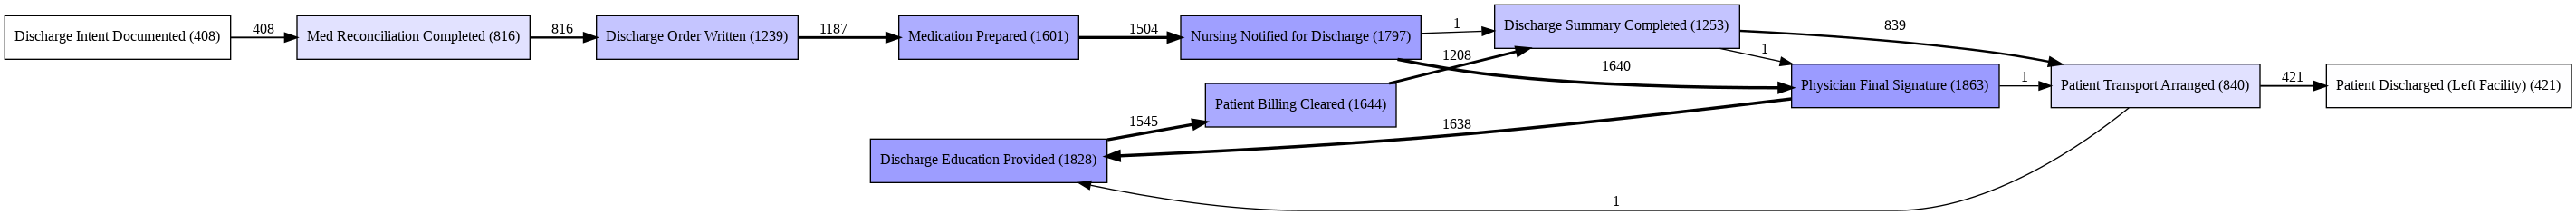

In [14]:
Image(filename=str(config.OUTPUT_DIR / "figures" / "original_frequency_dfg.png"))

Its activity counts sum to 13,710, matching the original row count. The flow is almost perfectly linear, with only three edges of count 1 deviating. This contradicts the presentation's claims of "spaghetti" complexity and 35% rework loops, which cannot have come from this dataset.

## 9. Save outputs

In [15]:
written = write_outputs(results, config.OUTPUT_DIR)
for name, path in written.items():
    print(f"{name:<25} {Path(path).relative_to(config.PROJECT_ROOT).as_posix()}")

data_quality_checks       outputs/reports/data_quality_checks.csv
rejected_records          outputs/reports/rejected_records.csv
activity_frequency        outputs/reports/activity_frequency.csv
directly_follows          outputs/reports/directly_follows.csv
variants                  outputs/reports/variants.csv
fig_activity_frequency    outputs/figures/activity_frequency.png
fig_variants              outputs/figures/top_variants.png
fig_dfg_matrix            outputs/figures/dfg_matrix.png
case_durations            outputs/reports/case_durations.csv
transition_gaps           outputs/reports/transition_gaps.csv
fig_case_durations        outputs/figures/case_duration_distribution.png
fig_transition_gaps       outputs/figures/transition_gaps.png
conformance_per_case      outputs/reports/conformance_per_case.csv
report                    outputs/reports/analysis_report.md


## 10. Conclusions

**Verified (about the code and the method):**
* The pipeline detects every injected data-quality problem, counts each one exactly, and never fills in or invents values.
* Control-flow results (variants, DFG) and timing results are separated, and timing is only computed when the timestamps support it.
* On synthetic data with known parameters, the bottleneck ranking recovers the designed slowest steps.

**About the original capstone data:** only control-flow facts can be stated: 13,710 events, 2,500 cases, 11 activities and a near-linear path. No timing, bottleneck, conformance or ROI figure from the original notebook or presentation is supported by the data.

**Recommendations (proposals, not measured outcomes):**
1. Obtain an extract with the real system timestamps (ideally both start and completion times) before drawing any conclusion about discharge delays.
2. Agree on the official discharge SOP as a reference model, so conformance can measure compliance and not just similarity to the usual path.
3. With real data, re-run this pipeline unchanged with `timestamp_provenance="original"`. The presentation's improvement ideas (starting pharmacy preparation earlier, EHR hard-stops) can then be tested against measured transition gaps instead of assumed ones.